# Geodesic distance by the heat method

`geodesic_distance(mesh, sources)` measures the distance **along a triangle surface** from source points to every point, and returns the mesh with `point_data["geodesic:distance"]`. It is Crane, Weischedel and Wardetzky's heat method ("Geodesics in Heat", 2013): a short heat flow from the sources, its normalised gradient, and a Poisson solve, all over the surface's own cotangent operators. See `doc/geodesic.md`.

In [1]:
import os
import subprocess
import sys
import tempfile

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

import meshioplusplus as mp


def gl_available():
    # Can PyVista render off-screen here? VTK without a GL/EGL/OSMesa library aborts
    # the process instead of raising, so the probe runs in a child process.
    probe = ("import pyvista as pv; pv.OFF_SCREEN = True; "
             "pl = pv.Plotter(off_screen=True, window_size=(64, 64)); "
             "pl.add_mesh(pv.Sphere()); pl.screenshot(return_img=True)")
    try:
        return subprocess.run([sys.executable, '-c', probe], capture_output=True, timeout=120).returncode == 0
    except Exception:
        return False


try:
    import pyvista as pv

    if gl_available():
        pv.OFF_SCREEN = True
        pv.set_jupyter_backend('static')
    else:
        pv = None
        print('No GL available: rendering with matplotlib.')
except ImportError:  # pragma: no cover - pyvista is optional here
    pv = None
    print('PyVista unavailable: rendering with matplotlib.')


def draw_surface(ax, mesh, values, title, cmap='magma', view=(20, 35)):
    """A triangle surface coloured by a point field: PyVista's render embedded
    as an image when GL is available, else a matplotlib Poly3DCollection."""
    tris = mesh.cells_dict['triangle']
    if pv is not None:
        faces = np.hstack([np.full((len(tris), 1), 3), tris]).ravel()
        grid = pv.PolyData(mesh.points, faces)
        grid.point_data['d'] = values
        pl = pv.Plotter(off_screen=True, window_size=(700, 600))
        pl.add_mesh(grid, scalars='d', cmap=cmap, show_edges=False, smooth_shading=True)
        pl.add_mesh(grid.contour(12, scalars='d'), color='white', line_width=2)
        ax.imshow(pl.screenshot(return_img=True))
        pl.close()
        ax.axis('off')
    else:
        face_values = values[tris].mean(axis=1)
        norm = plt.Normalize(np.nanmin(values), np.nanmax(values))
        coll = Poly3DCollection(mesh.points[tris], facecolors=plt.get_cmap(cmap)(norm(face_values)),
                                edgecolor='none')
        ax.add_collection3d(coll)
        lim = np.abs(mesh.points).max()
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_zlim(-lim, lim)
        ax.set_box_aspect((1, 1, 1))
        ax.view_init(*view)
        ax.set_axis_off()
        plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink=0.6, label='distance')
    ax.set_title(title)

No GL available: rendering with matplotlib.


## From the north pole of a sphere

On the unit sphere the exact geodesic distance from the north pole is the polar angle, `arccos(z)`, so the error can be read off directly. The sphere is an icosahedral one projected onto the unit sphere.

{'num_sources': 1, 'max_distance': 3.1165377976492645, 'time_step': 0.0014262987345436266, 'heat_iterations': 189, 'poisson_iterations': 274, 'converged': True}
pi = 3.1416; mean error 0.0111


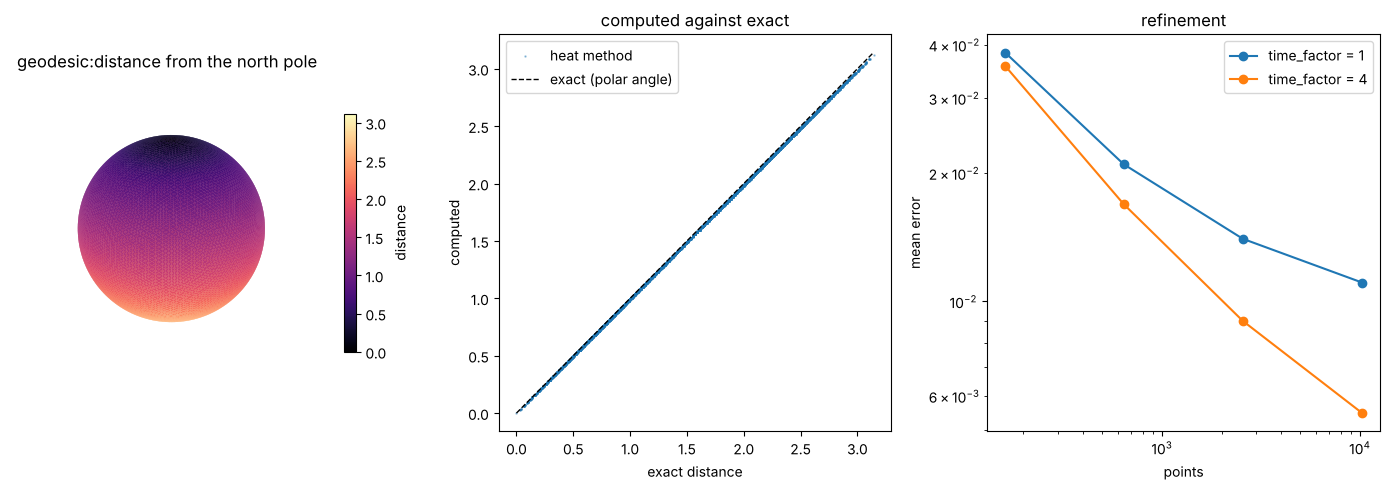

In [2]:
def unit_sphere(subdivisions):
    m = mp.icosa_sphere(subdivisions=subdivisions)
    p = m.points / np.linalg.norm(m.points, axis=1)[:, None]
    return mp.Mesh(p, m.cells)


sphere = unit_sphere(5)
pole = int(np.argmax(sphere.points[:, 2]))
out, report = mp.geodesic_distance(sphere, pole, return_report=True)
d = out.point_data['geodesic:distance']
exact = np.arccos(np.clip(sphere.points[:, 2], -1, 1))
print({k: report[k] for k in ('num_sources', 'max_distance', 'time_step', 'heat_iterations', 'poisson_iterations', 'converged')})
print(f'pi = {np.pi:.4f}; mean error {np.abs(d - exact).mean():.4f}')

fig = plt.figure(figsize=(14, 5))
ax = fig.add_subplot(1, 3, 1, projection=None if pv else '3d')
draw_surface(ax, out, d, 'geodesic:distance from the north pole')
ax = fig.add_subplot(1, 3, 2)
ax.plot(exact, d, '.', ms=1.5, alpha=0.4, label='heat method')
ax.plot([0, np.pi], [0, np.pi], 'k--', lw=1, label='exact (polar angle)')
ax.set_xlabel('exact distance'); ax.set_ylabel('computed'); ax.legend(); ax.set_title('computed against exact')
ax = fig.add_subplot(1, 3, 3)
for factor in (1.0, 4.0):
    subs, errors = [], []
    for sub in (2, 3, 4, 5):
        s = unit_sphere(sub)
        k = int(np.argmax(s.points[:, 2]))
        dd = mp.geodesic_distance(s, k, time_factor=factor).point_data['geodesic:distance']
        subs.append(len(s.points))
        errors.append(np.abs(dd - np.arccos(np.clip(s.points[:, 2], -1, 1))).mean())
    ax.loglog(subs, errors, 'o-', label=f'time_factor = {factor:g}')
ax.set_xlabel('points'); ax.set_ylabel('mean error'); ax.legend(); ax.set_title('refinement')
plt.tight_layout()
plt.show()

## Two sources, and the distance around a hole

Every point takes its nearest source, and the distance goes around holes rather than through them: on a plate with a hole, the points straight across the hole from a source are farther away than their straight-line distance.

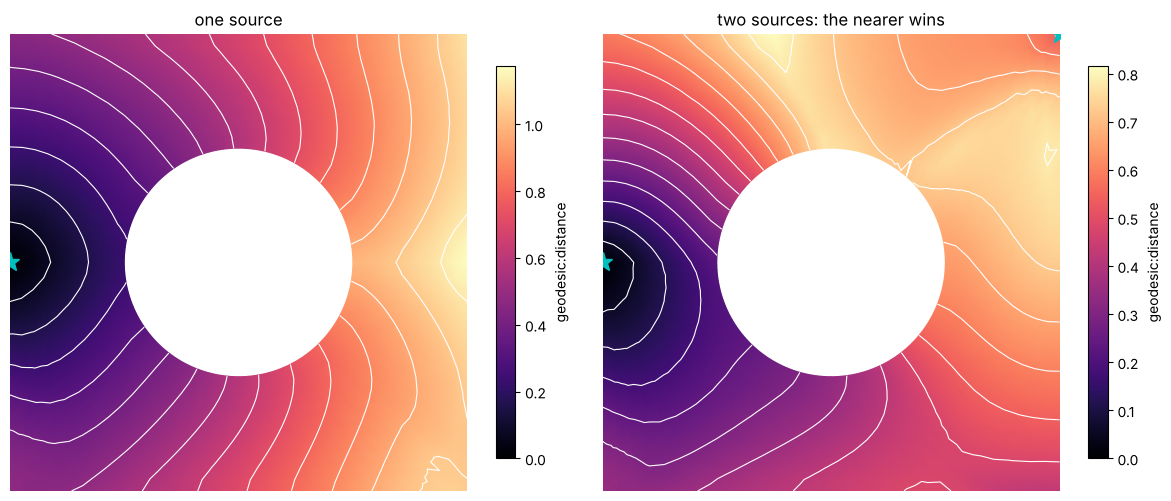

In [3]:
plate, _ = mp.apply_operations(None, [
    {"Op": "Generate", "Shape": "plate_with_hole", "Nt": 24, "Nr": 10},
    {"Op": "ConvertCells", "Mode": "simplexify"},
])
pts = plate.points
left = int(np.argmin(np.linalg.norm(pts[:, :2] - [-0.5, 0.0], axis=1)))
right_top = int(np.argmin(np.linalg.norm(pts[:, :2] - [0.5, 0.5], axis=1)))
d_one = mp.geodesic_distance(plate, left).point_data['geodesic:distance']
d_two = mp.geodesic_distance(plate, [left, right_top]).point_data['geodesic:distance']
tris = plate.cells_dict['triangle']

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, values, srcs, title in ((axes[0], d_one, [left], 'one source'), (axes[1], d_two, [left, right_top], 'two sources: the nearer wins')):
    tc = ax.tripcolor(pts[:, 0], pts[:, 1], tris, values, shading='gouraud', cmap='magma')
    ax.tricontour(pts[:, 0], pts[:, 1], tris, values, levels=14, colors='white', linewidths=0.8)
    ax.plot(pts[srcs, 0], pts[srcs, 1], 'c*', ms=14)
    ax.set_aspect('equal'); ax.set_title(title); ax.axis('off')
    plt.colorbar(tc, ax=ax, shrink=0.8, label='geodesic:distance')
plt.tight_layout()
plt.show()